# CXR-Sentry · Section 3: report sampling and uncertainty (FINAL)

This notebook continues from baseline generator handoff (`iu-baseline-100ep-seed42`, commit `46e3d8c`). It covers:

1. Five sampled reports per study from baseline's checkpoint, with temperature, top-p, seed, output length and checkpoint version recorded.
2. One shared **CheXbert** wrapper, used for reference, greedy and sampled reports. It keeps all four states: positive, negative, uncertain and unmentioned.
3. **Finding-state entropy** per finding, aggregated to one score per report.
4. **Bidirectional NLI** checks, deterministic semantic clustering and **semantic entropy** per report.
5. A sampling-sensitivity check on **dev**, a frozen setting, then the **test** split.
6. Handoff files for Person 2 (labels) and Person 4 (labels and uncertainty scores).

**Before you start, put these in Google Drive** (the paths can be changed in Step 3):

```
MyDrive/CXR-Sentry/handoff/
├── iu-baseline-100ep-seed42.zip   ← the zip baseline shared (checkpoint, its own train/dev manifest, greedy drafts)
└── manifest_full.csv              ← the team's official 5-split manifest (uid, filename, findings, impression, split, ...)
```

**Images:** put the IU PNG images in `MyDrive/CXR-Sentry/handoff/images/`, as one zip, several zips (Drive splits big downloads) or loose PNGs. The notebook copies only the PNGs the manifest uses to Colab's local disk. If you can see Samarth's MLH folder from this account instead, set `IMAGES_SRC = Path("/content/drive/MyDrive/MLH/dataset/NLMCXR_png")` in Step 3.

**Runtime:** Runtime → Change runtime type → **GPU** (A100 or L4 is fastest; T4 also works).

Every output is saved under `MyDrive/CXR-Sentry/person3_outputs/`. Sampling is **resumable**: if Colab disconnects, rerun Steps 1–7 and sampling picks up where it stopped.

## Step 1: Check the GPU

In [1]:
!nvidia-smi

Mon Nov 23 19:24:10 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  NVIDIA L4                      Off |   00000000:00:03.0 Off |                    0 |
| N/A   62C    P8             14W /   72W |       0MiB /  23034MiB |      0%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

## Step 2: Install the same library versions trained with
These versions match the `environment.txt`. Colab's own `torch` is kept.
If the cell prints a ⚠️ line or pip asks you to restart, use **Runtime → Restart session**, then continue from Step 3. Don't rerun this cell. (`torchao` is upgraded too, because PEFT's version check needs it on Colab.)

In [ ]:
!pip install -q transformers==5.23.0 peft==0.21.3 huggingface_hub==2.4.0 torchxrayvision==1.5.7 sentencepiece==0.2.3 "torchao>=0.16.0"
import torch, transformers, peft, torchxrayvision
print("torch", torch.__version__, "| transformers", transformers.__version__, "| peft", peft.__version__,
      "| torchxrayvision", torchxrayvision.__version__, "| CUDA:", torch.cuda.is_available())
if transformers.__version__ != "5.23.0":
    print("⚠️ transformers is", transformers.__version__, "not 5.23.0 → Runtime → Restart session, then continue from Step 3.")

## Step 3: Mount Drive and set the configuration
**Check `FINDINGS` and `AGGREGATION` against the proposal.** The defaults are the five CheXpert competition findings and a mean over findings. Change them here if the proposal says otherwise, before generating any results.

In [28]:
from google.colab import drive
drive.mount("/content/drive")

from pathlib import Path
import shutil

# ---- Paths: edit if your Drive layout is different ----
DRIVE_ROOT   = Path("/content/drive/MyDrive/CXR-Sentry")
HANDOFF_DIR  = DRIVE_ROOT / "handoff"
HANDOFF_ZIP  = HANDOFF_DIR / "iu-baseline-100ep-seed42.zip"
# Images: a folder of PNGs, a folder of zips (e.g. Drive's split download), or one zip.
IMAGES_SRC   = Path("/content/drive/MyDrive/MLH/dataset/NLMCXR_png")   # your MLH shortcut
OFFICIAL_MANIFEST = HANDOFF_DIR / "manifest_full.csv"   # the team's official train/dev/prob_cal/risk_cal/test split
SPLITS_DIR   = HANDOFF_DIR / "splits"   # optional extra split CSVs (normally empty)
OUT_DIR      = DRIVE_ROOT / "person3_outputs"

LOCAL    = Path("/content/work")          # fast local disk for images
REPO_DIR = Path("/content/CXR-Sentry")

# ---- Generator version (from latest git_commit.txt and checkpoint) ----
GENERATOR_COMMIT = "46e3d8c62ec18e9d3f943da07c80e0d157cb4a28"
CHECKPOINT_ID    = "iu-baseline-100ep-seed42"

# ---- Study settings: confirm with the proposal ----
FINDINGS    = ["Atelectasis", "Cardiomegaly", "Consolidation", "Edema", "Pleural Effusion"]
AGGREGATION = "mean"        # report-level finding-state entropy: "mean", "max" or "sum" over FINDINGS
NUM_SAMPLES = 5
MAX_NEW_TOKENS = 128        # same limit as the greedy exports
BASE_SEED   = 42

# Sampling settings compared on DEV only. Key = tag used in file names.
SAMPLING_GRID = {
    "t0.7_p0.90": (0.7, 0.90),   # generate.py default
    "t1.0_p0.95": (1.0, 0.95),
    "t1.0_p1.00": (1.0, 1.00),
    "t1.3_p1.00": (1.3, 1.00),
}

NLI_MODEL = "MoritzLaurer/DeBERTa-v3-base-mnli-fever-anli"   # proposal ref [5]

# The checkpoint was trained on a different split than the official one. Studies it was TRAINED on
# must not be used to judge it (that would be leakage). True = leave them out of every generator-based
# output (greedy, samples, uncertainty). Reference labels are still made for every study.
EXCLUDE_GENERATOR_TRAINING_STUDIES = True
FINAL_SPLITS = ["test", "risk_cal"]   # splits that get samples + uncertainty after freezing (Person 4 needs risk_cal)
BOOTSTRAP_REPS = 1000                 # for the AUROC confidence intervals in Step 12
CHEXBERT_REPO, CHEXBERT_FILE = "StanfordAIMI/RRG_scorers", "chexbert.pth"
DEVICE = "cuda"

for sub in ("samples", "labels", "uncertainty", "greedy", "validation", "nli_cache"):
    (OUT_DIR / sub).mkdir(parents=True, exist_ok=True)
SPLITS_DIR.mkdir(parents=True, exist_ok=True)
assert HANDOFF_ZIP.exists(), f"Upload the generator checkpoint zip to {HANDOFF_ZIP}"
assert IMAGES_SRC.exists(), f"Images not found at {IMAGES_SRC}. Put the image zip(s) there (or fix IMAGES_SRC)"
print("Config OK. Outputs go to", OUT_DIR)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Config OK. Outputs go to /content/drive/MyDrive/CXR-Sentry/person3_outputs


## Step 4: Get Baseline's code at the exact commit that trained the checkpoint

In [29]:
import os, sys, subprocess, shutil

if not REPO_DIR.exists():
    subprocess.run(["git", "clone", "-q", "-b", "Shivank/Generator",
                    "https://github.com/Shivank19/CXR-Sentry.git", str(REPO_DIR)], check=True)
subprocess.run(["git", "-C", str(REPO_DIR), "checkout", "-q", GENERATOR_COMMIT], check=True)
print(subprocess.run(["git", "-C", str(REPO_DIR), "log", "-1", "--oneline"],
                     capture_output=True, text=True).stdout)

src = str(REPO_DIR / "src")
if src not in sys.path:
    sys.path.insert(0, src)
os.environ["PYTHONPATH"] = src

46e3d8c Add prepared dataset manifest conversion



## Step 5: Unpack the checkpoint, build the official manifest, copy images
- Reads the team's official split from `handoff/manifest_full.csv`: `uid → study_id "CXR<uid>"`, `findings` + `impression` → `"Findings: …\nImpression: …"` (exactly baseline's format), `development/prob_calibration/risk_calibration` → `dev/prob_cal/risk_cal`.
- Matches images by study number + `IM-xxxx-xxxx`, so `1_IM-0001-4001.dcm.png` finds `CXR1_1_IM-0001-4001.png` in the IU folder.
- Compares the official split with the studies the checkpoint was **trained on** (from the work of task 2 manifest) and saves `validation/generator_overlap.csv`.

In [30]:
import zipfile, shutil, csv, json, hashlib, re
import pandas as pd
from tqdm.auto import tqdm

LOCAL.mkdir(parents=True, exist_ok=True)
RUN_DIR = LOCAL / "iu-baseline-100ep-seed42"
if not RUN_DIR.exists():
    with zipfile.ZipFile(HANDOFF_ZIP) as z:
        z.extractall(LOCAL)
CHECKPOINT = RUN_DIR / "best_checkpoint"
assert (CHECKPOINT / "config.json").exists(), "best_checkpoint/ not found in the zip"
IMAGE_ROOT = LOCAL / "images"
IMAGE_ROOT.mkdir(exist_ok=True)

def read_csv(path):
    # keep_default_na=False keeps blank cells as "" (e.g. blank mean_nll), not NaN
    return pd.read_csv(path, dtype=str, keep_default_na=False, encoding="utf-8-sig")

VALID = {"train", "dev", "prob_cal", "risk_cal", "test"}
SPLIT_ALIASES = {"development": "dev", "validation": "dev", "val": "dev",
                 "prob_calibration": "prob_cal", "probability_calibration": "prob_cal",
                 "risk_calibration": "risk_cal"}   # calibration splits stay separate, never merged into train

def squash(text):
    return re.sub(r"\s+", " ", str(text)).strip()

def report_text(findings, impression):
    # Same format as Person 2's manifest: "Findings: ...\nImpression: ..." (a missing section is left out)
    parts = []
    if squash(findings):
        parts.append("Findings: " + squash(findings))
    if squash(impression):
        parts.append("Impression: " + squash(impression))
    return "\n".join(parts)

def read_split_file(path):
    # Accepts (1) the team's official manifest (uid, filename, findings, impression, split, ...),
    # (2) Required format (study_id, image_path, split, reference_text), or
    # (3) prepare_manifest.py's format (study_id, image_path, target_text, view_label).
    df = read_csv(path)
    cols = set(df.columns)
    if {"uid", "filename", "findings", "impression", "split"} <= cols:
        if "projection_norm" in cols:
            assert (df["projection_norm"].str.lower() == "frontal").all(), f"{path.name}: non-frontal rows"
        if "eligible" in cols:
            df = df[df["eligible"].str.lower() == "true"]
        df = pd.DataFrame({
            "study_id": "CXR" + df["uid"].str.strip(),
            "image_path": df["filename"].str.strip(),
            "split": df["split"],
            "reference_text": [report_text(f, i) for f, i in zip(df["findings"], df["impression"])],
        })
    else:
        if "reference_text" not in cols and "target_text" in cols:
            df = df.rename(columns={"target_text": "reference_text"})
        if "split" not in df.columns:
            df["split"] = path.stem               # test.csv -> "test"
        if "view_label" in df.columns:
            assert (df["view_label"].str.upper() == "FRONTAL").all(), f"{path.name}: non-frontal rows"
        missing = {"study_id", "image_path", "split", "reference_text"} - set(df.columns)
        assert not missing, f"{path.name} is missing columns {sorted(missing)}"
        df = df[["study_id", "image_path", "split", "reference_text"]].copy()
    df = df.apply(lambda c: c.str.strip())
    df["split"] = df["split"].str.lower().replace(SPLIT_ALIASES)
    assert set(df["split"]) <= VALID, f"{path.name}: unknown split names {set(df['split']) - VALID}"
    blank = df["reference_text"].str.lower().isin(["", "no reference text available.", "nan", "none"])
    assert not blank.any(), f"{path.name}: {blank.sum()} rows have no real reference text"
    return df

# What the checkpoint was trained (train) and checkpoint-selected (dev) on
generator_manifest = read_csv(RUN_DIR / "manifest.csv")
GEN_TRAIN_IDS = set(generator_manifest.loc[generator_manifest.split == "train", "study_id"])
GEN_DEV_IDS = set(generator_manifest.loc[generator_manifest.split == "dev", "study_id"])

sources = ([OFFICIAL_MANIFEST] if OFFICIAL_MANIFEST.exists() else []) + sorted(SPLITS_DIR.glob("*.csv"))
if sources:
    manifest = pd.concat([read_split_file(p) for p in sources], ignore_index=True)
    OFFICIAL = True
    print("Official split from:", [p.name for p in sources])
else:
    manifest = generator_manifest[["study_id", "image_path", "split", "reference_text"]].copy()
    OFFICIAL = False
    print("⚠️ No official manifest found: using the generator's original train/dev split (provisional, no test).")
dups = manifest["study_id"][manifest["study_id"].duplicated()]
assert dups.empty, f"duplicate study_id across files, e.g. {dups.tolist()[:5]}"

manifest["generator_trained_on"] = manifest["study_id"].isin(GEN_TRAIN_IDS)
manifest["generator_dev"] = manifest["study_id"].isin(GEN_DEV_IDS)
overlap = manifest.groupby("split").agg(studies=("study_id", "size"),
                                        generator_trained_on=("generator_trained_on", "sum"),
                                        generator_dev=("generator_dev", "sum"))
overlap["usable_for_generator_eval"] = overlap["studies"] - (overlap["generator_trained_on"] if EXCLUDE_GENERATOR_TRAINING_STUDIES else 0)
overlap.to_csv(OUT_DIR / "validation" / "generator_overlap.csv")
print(overlap)
EXCLUDED_IDS = set(manifest.loc[manifest.generator_trained_on & (manifest.split != "train"), "study_id"]) \
    if EXCLUDE_GENERATOR_TRAINING_STUDIES else set()
if OFFICIAL and overlap.loc[overlap.index != "train", "generator_trained_on"].sum() > 0:
    print("\n⚠️ The checkpoint was trained on", int(overlap.loc[overlap.index != "train", "generator_trained_on"].sum()),
          "studies that are in the official dev/calibration/test splits.",
          "\n   They are EXCLUDED from generator-based outputs" if EXCLUDE_GENERATOR_TRAINING_STUDIES else "\n   They are NOT excluded (results will be optimistic)",
          "\n   Proper fix: Retrain the generator on the official train split, then rerun this notebook.")
# ---- images: match by (study number, IM-xxxx-xxxx), so Kaggle-style and NLMCXR-style names both work ----
KEY_RE = re.compile(r"(?:CXR)?(\d+)_(?:\d+_)?(IM-\d+-\d+)", re.I)
def image_key(name):
    name = str(name).replace("\\", "/").split("/")[-1]
    m = KEY_RE.search(name)
    return (m.group(1), m.group(2).upper()) if m else name.lower()

needed = {image_key(x) for x in manifest["image_path"]} | {image_key(x) for x in generator_manifest["image_path"]}
if IMAGES_SRC.suffix.lower() == ".zip":
    zip_files, png_files = [IMAGES_SRC], {}
else:
    zip_files = sorted(IMAGES_SRC.rglob("*.zip"))
    png_files = {image_key(p.name): p for p in IMAGES_SRC.rglob("*.png")}
for zp in zip_files:
    with zipfile.ZipFile(zp) as z:
        members = [m for m in z.namelist() if m.lower().endswith(".png") and image_key(m) in needed]
        for m in tqdm(members, desc=f"Unzipping needed PNGs from {zp.name}"):
            target = IMAGE_ROOT / m.split("/")[-1]
            if not target.exists():
                target.write_bytes(z.read(m))
for key in tqdm(sorted(needed & set(png_files), key=str), desc="Copying needed PNGs from Drive"):
    target = IMAGE_ROOT / png_files[key].name
    if not target.exists():
        shutil.copy(png_files[key], target)
local_index = {image_key(p.name): p.name for p in IMAGE_ROOT.glob("*.png")}

def localize(df):
    out = df.copy()
    out["image_path"] = [local_index.get(image_key(x), x) for x in df["image_path"]]
    out["image_found"] = [image_key(x) in local_index for x in df["image_path"]]
    return out

manifest_local = localize(manifest)
MANIFEST_LOCAL = LOCAL / "manifest_local.csv"
manifest_local[["study_id", "image_path", "split", "reference_text"]].to_csv(MANIFEST_LOCAL, index=False)
GEN_MANIFEST_LOCAL = LOCAL / "generator_manifest_local.csv"
localize(generator_manifest)[["study_id", "image_path", "split", "reference_text"]].to_csv(GEN_MANIFEST_LOCAL, index=False)

summary = manifest_local.groupby("split")["image_found"].agg(studies="size", images_found="sum")
print(summary)
SPLITS = set(manifest_local["split"])
for split in SPLITS:
    n_missing = summary.loc[split, "studies"] - summary.loc[split, "images_found"]
    assert split == "train" or n_missing == 0, f"{n_missing} {split} images are missing from {IMAGES_SRC}"

def sha12(path):
    with open(path, "rb") as f:
        return hashlib.file_digest(f, "sha256").hexdigest()[:12]
CHECKPOINT_SHA = sha12(CHECKPOINT / "lora" / "adapter_model.safetensors") + "-" + sha12(CHECKPOINT / "visual_tokenizer.pt")
print("Checkpoint fingerprint:", CHECKPOINT_SHA)

Official split from: ['manifest_full.csv']
          studies  generator_trained_on  generator_dev  \
split                                                    
dev           366                   202             38   
prob_cal      366                   207             41   
risk_cal      367                   206             28   
test          551                   293             62   
train        2016                  1108            198   

          usable_for_generator_eval  
split                                
dev                             164  
prob_cal                        159  
risk_cal                        161  
test                            258  
train                           908  

⚠️ The checkpoint was trained on 908 studies that are in the official dev/calibration/test splits. 
   They are EXCLUDED from generator-based outputs 
   Proper fix: Retrain the generator on the official train split, then rerun this notebook.


Copying needed PNGs from Drive:   0%|          | 0/3668 [00:00<?, ?it/s]

          studies  images_found
split                          
dev           366           366
prob_cal      366           366
risk_cal      367           367
test          551           551
train        2016          2016
Checkpoint fingerprint: db2f4c237d4f-a3a2ee047d65


## Step 6: Load the generator and check it reproduces BASELINE'S greedy drafts
This reruns greedy decoding on 10 dev studies and compares the output with `greedy_dev.csv`. A full match means your Colab setup matches the environment. A few mismatches can come from GPU numerics; many mismatches mean something is wrong.

In [31]:
!pip install -q transformers==5.23.0 peft==0.21.3 huggingface_hub==2.4.0 torchxrayvision==1.5.7 sentencepiece==0.2.3

In [32]:
# Upgrade torchao to satisfy PEFT dependency version checks, then restart or re-import
!pip install -U -q torchao>=0.16.0
import torchao
print("Upgraded torchao version to:", torchao.__version__)

Upgraded torchao version to: 0.18.0


In [33]:
import torch
from tqdm.auto import tqdm
from cxr_sentry.generator.generate import load_generator, generate_token_ids
from cxr_sentry.generator.export import score_greedy_draft
from cxr_sentry.generator.dataset import CXRManifestDataset

generator, gen_tokenizer = load_generator(CHECKPOINT, DEVICE)
EOS_ID = generator.t5.config.eos_token_id

greedy_dev = read_csv(RUN_DIR / "greedy_dev.csv").set_index("study_id")
dev_ds = CXRManifestDataset(GEN_MANIFEST_LOCAL, IMAGE_ROOT, "dev")   # Person 2's own dev, which his export covers
matches = 0
for i in range(10):
    ex = dev_ds[i]
    seq = generate_token_ids(generator, ex["image"].unsqueeze(0).to(DEVICE), max_new_tokens=MAX_NEW_TOKENS)[0]
    text = gen_tokenizer.decode(seq.cpu().tolist(), skip_special_tokens=True)
    same = text == greedy_dev.loc[ex["study_id"], "generated_text"]
    matches += same
    if not same:
        print("MISMATCH", ex["study_id"], "\n  colab  :", text, "\n  export:", greedy_dev.loc[ex["study_id"], "generated_text"])
print(f"{matches}/10 greedy drafts match referenced export")

def eval_dataset(split):
    # Official split, minus studies the generator was trained on (if EXCLUDE_GENERATOR_TRAINING_STUDIES)
    ds = CXRManifestDataset(MANIFEST_LOCAL, IMAGE_ROOT, split)
    ds.rows = [r for r in ds.rows if r[0] not in EXCLUDED_IDS]
    return ds

GREEDY_NEW = OUT_DIR / "greedy" / "greedy_generated.csv"
def all_greedy():
    # Greedy decoding is deterministic, so a draft is valid whatever split label it was exported under.
    files = sorted(set(RUN_DIR.glob("greedy_*.csv")) | set(HANDOFF_DIR.glob("greedy_*.csv"))
                   | set((OUT_DIR / "greedy").glob("greedy_*.csv")))
    g = pd.concat([read_csv(p) for p in files], ignore_index=True).drop_duplicates("study_id", keep="last")
    return g, files

def ensure_greedy(split):
    # Generate greedy drafts (same functions as export.py) for usable studies that lack one.
    have = set(all_greedy()[0]["study_id"])
    ds = eval_dataset(split)
    todo = [i for i, r in enumerate(ds.rows) if r[0] not in have]
    print(f"{split}: {len(ds.rows)} usable studies, {len(ds.rows) - len(todo)} already have a greedy draft, generating {len(todo)}")
    new_file = not GREEDY_NEW.exists()
    with GREEDY_NEW.open("a", encoding="utf-8", newline="") as f:
        w = csv.DictWriter(f, fieldnames=["study_id", "split", "checkpoint_id", "generated_text", "mean_nll", "n_tokens"])
        if new_file:
            w.writeheader()
        for i in tqdm(todo, desc=f"greedy {split}"):
            ex = ds[i]
            images = ex["image"].unsqueeze(0).to(DEVICE)
            seq = generate_token_ids(generator, images, max_new_tokens=MAX_NEW_TOKENS)[0]
            mean_nll, n_tokens = score_greedy_draft(generator, images, seq)
            w.writerow({"study_id": ex["study_id"], "split": split, "checkpoint_id": CHECKPOINT_ID,
                        "generated_text": gen_tokenizer.decode(seq.cpu().tolist(), skip_special_tokens=True),
                        "mean_nll": "" if mean_nll is None else mean_nll, "n_tokens": n_tokens})
            f.flush()

Loading weights:   0%|          | 0/190 [00:00<?, ?it/s]

[transformers] The tied weights mapping and config for this model specifies to tie shared.weight to lm_head.weight, but both are present in the checkpoints with different values, so we will NOT tie them. You should update the config with `tie_word_embeddings=False` to silence this warning.


10/10 greedy drafts match referenced export


## Step 7: Define the sampling function (resumable)
Each study gets its own fixed seed, derived from `BASE_SEED` and its `study_id`. The same seed is used under every sampling setting, so the settings are compared on equal terms.

In [34]:
SAMPLE_COLUMNS = [
    "study_id", "split", "checkpoint_id", "checkpoint_sha", "generator_commit",
    "sampling_tag", "temperature", "top_p", "top_k", "num_samples", "max_new_tokens",
    "seed", "sample_index", "generated_text", "n_tokens", "n_words", "mean_nll", "hit_max_new_tokens",
]

def study_seed(study_id: str) -> int:
    digest = int(hashlib.sha256(study_id.encode()).hexdigest()[:8], 16)
    return (BASE_SEED * 1_000_003 + digest) % (2**31 - 1)

def samples_path(split, tag):
    return OUT_DIR / "samples" / f"samples_{split}_{tag}.csv"

def sample_split(split, tag, temperature, top_p):
    out = samples_path(split, tag)
    done = set()
    if out.exists():
        old = read_csv(out)
        counts = old.groupby("study_id").size()
        complete = counts[counts == NUM_SAMPLES].index
        old = old[old["study_id"].isin(complete)]
        old.to_csv(out, index=False)          # drop any half-written study
        done = set(complete)

    ds = eval_dataset(split)
    new_file = not out.exists()
    with out.open("a", encoding="utf-8", newline="") as f:
        writer = csv.DictWriter(f, fieldnames=SAMPLE_COLUMNS)
        if new_file:
            writer.writeheader()
        for i in tqdm(range(len(ds)), desc=f"{split} {tag}"):
            study_id = ds.rows[i][0]
            if study_id in done:
                continue
            ex = ds[i]
            images = ex["image"].unsqueeze(0).to(DEVICE)
            seed = study_seed(study_id)
            torch.manual_seed(seed)
            seqs = generate_token_ids(generator, images, max_new_tokens=MAX_NEW_TOKENS,
                                      num_samples=NUM_SAMPLES, temperature=temperature, top_p=top_p)
            rows = []
            for k, seq in enumerate(seqs):
                mean_nll, n_tokens = score_greedy_draft(generator, images, seq)  # scores any generated sequence
                text = gen_tokenizer.decode(seq.cpu().tolist(), skip_special_tokens=True)
                rows.append({
                    "study_id": study_id, "split": split, "checkpoint_id": CHECKPOINT_ID,
                    "checkpoint_sha": CHECKPOINT_SHA, "generator_commit": GENERATOR_COMMIT,
                    "sampling_tag": tag, "temperature": temperature, "top_p": top_p, "top_k": 0,
                    "num_samples": NUM_SAMPLES, "max_new_tokens": MAX_NEW_TOKENS, "seed": seed,
                    "sample_index": k, "generated_text": text, "n_tokens": n_tokens,
                    "n_words": len(text.split()), "mean_nll": "" if mean_nll is None else mean_nll,
                    "hit_max_new_tokens": not bool((seq[1:] == EOS_ID).any().item()),
                })
            writer.writerows(rows)
            f.flush()
    print("Saved", out)

## Step 8: Sample dev under every setting (sensitivity check)
Generates any missing greedy drafts for dev, then samples. Expect a few minutes per setting on an A100 or L4. Only dev is sampled here; test and risk_cal are not touched until the setting is frozen in Step 13.

In [35]:
ensure_greedy("dev")   # official dev studies outside dev have no greedy draft yet
for tag, (t, p) in SAMPLING_GRID.items():
    sample_split("dev", tag, t, p)

with (OUT_DIR / "samples" / "sampling_grid.json").open("w") as f:
    json.dump({"grid": SAMPLING_GRID, "num_samples": NUM_SAMPLES, "max_new_tokens": MAX_NEW_TOKENS,
               "top_k": 0, "base_seed": BASE_SEED, "seed_rule": "(BASE_SEED*1000003 + int(sha256(study_id)[:8],16)) % (2**31-1)",
               "checkpoint_id": CHECKPOINT_ID, "checkpoint_sha": CHECKPOINT_SHA,
               "generator_commit": GENERATOR_COMMIT}, f, indent=2)

dev: 164 usable studies, 164 already have a greedy draft, generating 0


greedy dev: 0it [00:00, ?it/s]

dev t0.7_p0.90:   0%|          | 0/164 [00:00<?, ?it/s]

Saved /content/drive/MyDrive/CXR-Sentry/person3_outputs/samples/samples_dev_t0.7_p0.90.csv


dev t1.0_p0.95:   0%|          | 0/164 [00:00<?, ?it/s]

Saved /content/drive/MyDrive/CXR-Sentry/person3_outputs/samples/samples_dev_t1.0_p0.95.csv


dev t1.0_p1.00:   0%|          | 0/164 [00:00<?, ?it/s]

Saved /content/drive/MyDrive/CXR-Sentry/person3_outputs/samples/samples_dev_t1.0_p1.00.csv


dev t1.3_p1.00:   0%|          | 0/164 [00:00<?, ?it/s]

Saved /content/drive/MyDrive/CXR-Sentry/person3_outputs/samples/samples_dev_t1.3_p1.00.csv


## Step 9: The shared CheXbert labeler
This is the original CheXbert architecture (BERT-base plus 14 heads), loaded from the public `StanfordAIMI/RRG_scorers` weights.
States: `0 → unmentioned, 1 → positive, 2 → negative, 3 → uncertain`. "No Finding" has only two classes (unmentioned or positive).

In [36]:
import re, math
from torch import nn
from transformers import AutoTokenizer, BertModel
from huggingface_hub import hf_hub_download

CHEXBERT_CONDITIONS = [
    "Enlarged Cardiomediastinum", "Cardiomegaly", "Lung Opacity", "Lung Lesion", "Edema",
    "Consolidation", "Pneumonia", "Atelectasis", "Pneumothorax", "Pleural Effusion",
    "Pleural Other", "Fracture", "Support Devices", "No Finding",
]
CLASS_TO_STATE = {0: "unmentioned", 1: "positive", 2: "negative", 3: "uncertain"}
STATES = ["positive", "negative", "uncertain", "unmentioned"]
assert set(FINDINGS) <= set(CHEXBERT_CONDITIONS)

def clean_text(text):
    return re.sub(r"\s+", " ", str(text)).strip()

class CheXbertLabeler(nn.Module):
    def __init__(self, device):
        super().__init__()
        self.tokenizer = AutoTokenizer.from_pretrained("bert-base-uncased")
        self.bert = BertModel.from_pretrained("bert-base-uncased")
        hidden = self.bert.config.hidden_size
        self.linear_heads = nn.ModuleList([nn.Linear(hidden, 4) for _ in range(13)] + [nn.Linear(hidden, 2)])

        path = hf_hub_download(CHEXBERT_REPO, CHEXBERT_FILE)
        try:
            ckpt = torch.load(path, map_location="cpu", weights_only=True)
        except Exception:
            ckpt = torch.load(path, map_location="cpu", weights_only=False)  # trusted StanfordAIMI file
        state = {k.replace("module.", ""): v for k, v in ckpt["model_state_dict"].items()}
        missing, unexpected = self.load_state_dict(state, strict=False)
        missing = [k for k in missing if "position_ids" not in k]
        unexpected = [k for k in unexpected if "position_ids" not in k]
        if missing or unexpected:
            raise RuntimeError(f"CheXbert weights did not load cleanly. missing={missing[:5]} unexpected={unexpected[:5]}")
        self.version = f"CheXbert {CHEXBERT_REPO}/{CHEXBERT_FILE} sha256:{sha12(path)}"
        self.device = device
        self.to(device).eval()

    @torch.inference_mode()
    def label(self, texts, batch_size=64):
        # Many reports repeat word-for-word, so each distinct text is labeled once.
        cleaned = [clean_text(t) for t in texts]
        unique = list(dict.fromkeys(cleaned))
        cache = {}
        for start in tqdm(range(0, len(unique), batch_size), desc="CheXbert", leave=False):
            chunk = unique[start:start + batch_size]
            enc = self.tokenizer(chunk, padding=True, truncation=True, max_length=512,
                                 return_tensors="pt").to(self.device)
            cls = self.bert(input_ids=enc["input_ids"], attention_mask=enc["attention_mask"])[0][:, 0, :]
            preds = [head(cls).argmax(dim=1).tolist() for head in self.linear_heads]
            for j, text in enumerate(chunk):
                cache[text] = {c: CLASS_TO_STATE[preds[h][j]] for h, c in enumerate(CHEXBERT_CONDITIONS)}
        return [cache[t] for t in cleaned]

labeler = CheXbertLabeler(DEVICE)
print(labeler.version)

# Quick check: read these by eye
checks = ["Mild cardiomegaly. No pleural effusion.",
          "Possible left basilar atelectasis.",
          "The heart is normal in size. The lungs are clear. No acute disease."]
display(pd.DataFrame(labeler.label(checks), index=checks)[FINDINGS + ["No Finding"]])

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertModel LOAD REPORT from: bert-base-uncased
Key                                        | Status     |  | 
-------------------------------------------+------------+--+-
cls.predictions.transform.LayerNorm.weight | UNEXPECTED |  | 
cls.predictions.transform.dense.weight     | UNEXPECTED |  | 
cls.seq_relationship.weight                | UNEXPECTED |  | 
cls.predictions.transform.dense.bias       | UNEXPECTED |  | 
cls.seq_relationship.bias                  | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED |  | 
cls.predictions.bias                       | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


CheXbert StanfordAIMI/RRG_scorers/chexbert.pth sha256:6550703c92d6


CheXbert:   0%|          | 0/1 [00:00<?, ?it/s]

,Atelectasis,Cardiomegaly,Consolidation,Edema,Pleural Effusion,No Finding
Mild cardiomegaly. No pleural effusion.,unmentioned,positive,unmentioned,unmentioned,negative,unmentioned
Possible left basilar atelectasis.,uncertain,unmentioned,unmentioned,unmentioned,unmentioned,unmentioned
The heart is normal in size. The lungs are clear. No acute disease.,unmentioned,negative,unmentioned,unmentioned,unmentioned,positive


## Step 10: Label reference, greedy and sampled reports
This writes wide CSVs with one column per CheXbert condition, all 14 kept. Rerun the cell whenever new splits or new sample files arrive.

In [37]:
def add_labels(meta: pd.DataFrame, texts, source: str) -> pd.DataFrame:
    labels = labeler.label(list(texts))
    out = meta.reset_index(drop=True).copy()
    out.insert(2, "source", source)
    out["labeler"] = labeler.version
    for c in CHEXBERT_CONDITIONS:
        out[c] = [l[c] for l in labels]
    return out

def label_samples(path):
    s = read_csv(path)
    meta = s[["study_id", "split", "checkpoint_id", "sampling_tag", "sample_index", "seed"]]
    out = add_labels(meta, s["generated_text"], "sample")
    out.to_csv(OUT_DIR / "labels" / path.name.replace("samples_", "labels_samples_"), index=False)
    return out

def label_everything():
    # Label every reference report, greedy draft and sample file that exists right now.
    # 1) Reference reports for every split in the manifest (Person 2 needs prob_cal for calibration)
    ref = add_labels(manifest[["study_id", "split", "generator_trained_on", "generator_dev"]],
                     manifest["reference_text"], "reference")
    ref.to_csv(OUT_DIR / "labels" / "labels_reference.csv", index=False)
    print("reference:", ref.groupby("split").size().to_dict())

    # 2) Greedy drafts: Person 2's exports plus any greedy file in handoff/ or person3_outputs/greedy/
    greedy, files = all_greedy()
    # Use the OFFICIAL split label; keep only studies in the official manifest
    greedy = greedy.drop(columns="split").merge(
        manifest[["study_id", "split", "generator_trained_on", "generator_dev"]], on="study_id")
    gl = add_labels(greedy[["study_id", "split", "generator_trained_on", "generator_dev", "checkpoint_id",
                            "mean_nll", "n_tokens"]], greedy["generated_text"], "greedy")
    gl.to_csv(OUT_DIR / "labels" / "labels_greedy.csv", index=False)
    print("greedy:", gl.groupby("split").size().to_dict(), "from", [p.name for p in files])

    # 3) Every samples_*.csv
    for path in sorted((OUT_DIR / "samples").glob("samples_*.csv")):
        label_samples(path)
        print("labeled", path.name)

label_everything()

CheXbert:   0%|          | 0/46 [00:00<?, ?it/s]

reference: {'dev': 366, 'prob_cal': 366, 'risk_cal': 367, 'test': 551, 'train': 2016}


CheXbert:   0%|          | 0/2 [00:00<?, ?it/s]

greedy: {'dev': 366, 'prob_cal': 248, 'risk_cal': 367, 'test': 551, 'train': 1306} from ['greedy_generated.csv', 'greedy_dev.csv', 'greedy_train.csv']


CheXbert:   0%|          | 0/7 [00:00<?, ?it/s]

labeled samples_dev_t0.7_p0.90.csv


... (6 outputs left out)

CheXbert:   0%|          | 0/12 [00:00<?, ?it/s]

labeled samples_risk_cal_t1.0_p1.00.csv


CheXbert:   0%|          | 0/19 [00:00<?, ?it/s]

labeled samples_test_t1.0_p1.00.csv


## Step 11: Finding-state entropy and semantic entropy
- **Semantic entropy S (proposal, Section 4.3)**: samples are clustered in order with `MoritzLaurer/DeBERTa-v3-base-mnli-fever-anli`. A sample joins a cluster only if it entails, and is entailed by, **every** report already in that cluster. Identical texts skip the NLI step. Then S = −Σ p_c log p_c / log K with p_c = n_c / K and K = 5, so S is between 0 and 1.
- **Finding-state entropy (work plan, Person 3)**: for each finding, the entropy of its four-state distribution across the 5 samples, divided by log 4 so it's between 0 and 1. It is aggregated over `FINDINGS` with `AGGREGATION`. The proposal doesn't define this score, so agree the aggregation with your team.

In [38]:
from collections import Counter
from transformers import AutoModelForSequenceClassification

def entropy_from_counts(counts):
    n = sum(counts)
    return max(0.0, float(-sum((c / n) * math.log(c / n) for c in counts if c > 0)))   # no "-0.0"

def state_entropy(states):
    # Normalized by log(4 states) so each finding's entropy is in [0, 1], like S.
    return entropy_from_counts(Counter(states).values()) / math.log(len(STATES))

def aggregate(per_finding: pd.DataFrame, how: str) -> pd.Series:
    return {"mean": per_finding.mean(axis=1), "max": per_finding.max(axis=1),
            "sum": per_finding.sum(axis=1)}[how]

def finding_state_entropy(sample_labels: pd.DataFrame) -> pd.DataFrame:
    sizes = sample_labels.groupby("study_id").size()
    assert (sizes == NUM_SAMPLES).all(), "every study needs exactly NUM_SAMPLES labeled samples"
    per = sample_labels.groupby("study_id")[FINDINGS].agg(state_entropy)
    out = per.add_prefix("fse_")
    out["finding_state_entropy"] = aggregate(per, AGGREGATION)
    return out

class NLIJudge:
    def __init__(self, name, device):
        self.tokenizer = AutoTokenizer.from_pretrained(name)
        self.model = AutoModelForSequenceClassification.from_pretrained(name).to(device).eval()
        labels = {i: l.lower() for i, l in self.model.config.id2label.items()}
        self.entail_id = next(i for i, l in labels.items() if "entail" in l)
        self.device = device
        self.cache = {}

    @torch.inference_mode()
    def precompute(self, pairs, batch_size=32):
        todo = [p for p in dict.fromkeys(pairs) if p not in self.cache]
        for start in tqdm(range(0, len(todo), batch_size), desc="NLI", leave=False):
            chunk = todo[start:start + batch_size]
            enc = self.tokenizer([a for a, _ in chunk], [b for _, b in chunk], padding=True,
                                 truncation=True, max_length=512, return_tensors="pt").to(self.device)
            pred = self.model(**enc).logits.argmax(dim=-1).tolist()
            for pair, y in zip(chunk, pred):
                self.cache[pair] = (y == self.entail_id)

    def entails(self, premise, hypothesis):
        return self.cache[(premise, hypothesis)]

def same_text(a, b):
    return a.lower() == b.lower()

def needed_pairs(texts):
    keys = [clean_text(t) for t in texts]
    return [(a, b) for a in keys for b in keys if not same_text(a, b)]

def mutual(a, b, entails):
    return same_text(a, b) or (entails(a, b) and entails(b, a))

def cluster_texts(texts, entails):
    # Proposal 4.3: a report joins a cluster only if it is compatible (entailment in both
    # directions) with EVERY report already in that cluster. Deterministic: samples are
    # visited in sample_index order and the first compatible cluster wins.
    keys = [clean_text(t) for t in texts]
    clusters = []
    for i, k in enumerate(keys):
        for c in clusters:
            if all(mutual(k, keys[j], entails) for j in c):
                c.append(i)
                break
        else:
            clusters.append([i])
    assignment = [0] * len(keys)
    for cid, members in enumerate(clusters):
        for i in members:
            assignment[i] = cid
    return assignment

def semantic_entropy_frame(samples: pd.DataFrame, judge) -> pd.DataFrame:
    samples = samples.assign(_k=samples["sample_index"].astype(int)).sort_values(["study_id", "_k"])
    groups = {sid: g["generated_text"].tolist() for sid, g in samples.groupby("study_id", sort=False)}
    judge.precompute([p for texts in groups.values() for p in needed_pairs(texts)])
    rows = []
    for sid, texts in groups.items():
        assign = cluster_texts(texts, judge.entails)
        rows.append({"study_id": sid,
                     # Proposal 4.3: S = -sum p_c log p_c / log K, in [0, 1]
                     "semantic_entropy": entropy_from_counts(Counter(assign).values()) / math.log(len(texts)),
                     "n_semantic_clusters": len(set(assign)),
                     "n_unique_texts": len({clean_text(t).lower() for t in texts}),
                     "cluster_assignment": ",".join(map(str, assign))})
    return pd.DataFrame(rows).set_index("study_id")

nli = NLIJudge(NLI_MODEL, DEVICE)
nli_cache_file = OUT_DIR / "nli_cache" / "nli_cache.json"
if nli_cache_file.exists():
    nli.cache = {tuple(k.split("␞")): v for k, v in json.load(nli_cache_file.open()).items()}
print("NLI entailment label id:", nli.entail_id, nli.model.config.id2label)

Loading weights:   0%|          | 0/202 [00:00<?, ?it/s]

NLI entailment label id: 0 {0: 'entailment', 1: 'neutral', 2: 'contradiction'}


In [39]:
def uncertainty_path(split, tag):
    return OUT_DIR / "uncertainty" / f"uncertainty_{split}_{tag}.csv"

def build_uncertainty(split, tag):
    samples = read_csv(samples_path(split, tag))
    labels = read_csv(OUT_DIR / "labels" / f"labels_samples_{split}_{tag}.csv")
    fse = finding_state_entropy(labels)
    se = semantic_entropy_frame(samples, nli)
    lengths = samples.assign(n=samples["n_tokens"].astype(int),
                             hit=samples["hit_max_new_tokens"].astype(str).str.lower() == "true")
    lengths = lengths.groupby("study_id").agg(mean_sample_tokens=("n", "mean"), n_hit_max_new_tokens=("hit", "sum"))
    out = fse.join(se).join(lengths).reset_index()
    first = samples.iloc[0]
    out.insert(1, "split", split)
    out.insert(2, "checkpoint_id", CHECKPOINT_ID)
    out.insert(3, "sampling_tag", tag)
    out["temperature"], out["top_p"], out["num_samples"] = first["temperature"], first["top_p"], NUM_SAMPLES
    out["findings"] = "|".join(FINDINGS)
    out["aggregation"] = AGGREGATION
    out["nli_model"] = NLI_MODEL
    out.to_csv(uncertainty_path(split, tag), index=False)
    json.dump({"␞".join(k): v for k, v in nli.cache.items()}, nli_cache_file.open("w"))
    return out

In [40]:
for tag in SAMPLING_GRID:
    u = build_uncertainty("dev", tag)
    print(tag, "| mean FSE %.3f | mean SE %.3f" % (u.finding_state_entropy.mean(), u.semantic_entropy.mean()))

NLI: 0it [00:00, ?it/s]

t0.7_p0.90 | mean FSE 0.212 | mean SE 0.517


NLI: 0it [00:00, ?it/s]

t1.0_p0.95 | mean FSE 0.264 | mean SE 0.700


NLI: 0it [00:00, ?it/s]

t1.0_p1.00 | mean FSE 0.275 | mean SE 0.741


NLI: 0it [00:00, ?it/s]

t1.3_p1.00 | mean FSE 0.271 | mean SE 0.931


## Step 12: Sensitivity summary on dev (uncertainty validation)
Uses only dev studies the generator was **not** trained on. The **error proxy is preliminary** and only compares sampling settings; Person 4 owns the final one.
Following proposal Section 4.6, for each finding in `FINDINGS`: **unsupported** means greedy says *positive* while the reference denies or omits it. **Omission** means the reference says *positive* while greedy denies or omits it. Uncertain statements are left out; E = 1 if any finding meets either.

The figure has three panels:
- **A:** AUROC with 95% bootstrap intervals; greedy NLL doesn't depend on sampling, so it's a reference line.
- **B:** how many distinct meanings the 5 samples have.
- **C:** how often samples run into the 128-token limit.

Usable dev studies: 164 (excluded as generator-trained: 202)
Reference reports with a positive selected finding: 33 | preliminary errors: 33 (unsupported 0, omission 33)


,sampling_tag,studies,errors,AUROC_FSE,AUROC_FSE_lo,AUROC_FSE_hi,AUROC_SE,AUROC_SE_lo,AUROC_SE_hi,AUROC_greedyNLL,mean_semantic_clusters,pct_SE_max,pct_samples_hit_max_tokens
0,t0.7_p0.90,164,33,0.615,0.487,0.742,0.614,0.483,0.743,0.713,2.713,1.829,0.610
1,t1.0_p0.95,164,33,0.660,0.541,0.772,0.571,0.450,0.689,0.713,3.415,11.585,3.780
2,t1.0_p1.00,164,33,0.745,0.634,0.841,0.693,0.597,0.772,0.713,3.610,16.463,5.732
3,t1.3_p1.00,164,33,0.514,0.387,0.637,0.577,0.489,0.661,0.713,4.610,65.244,59.268


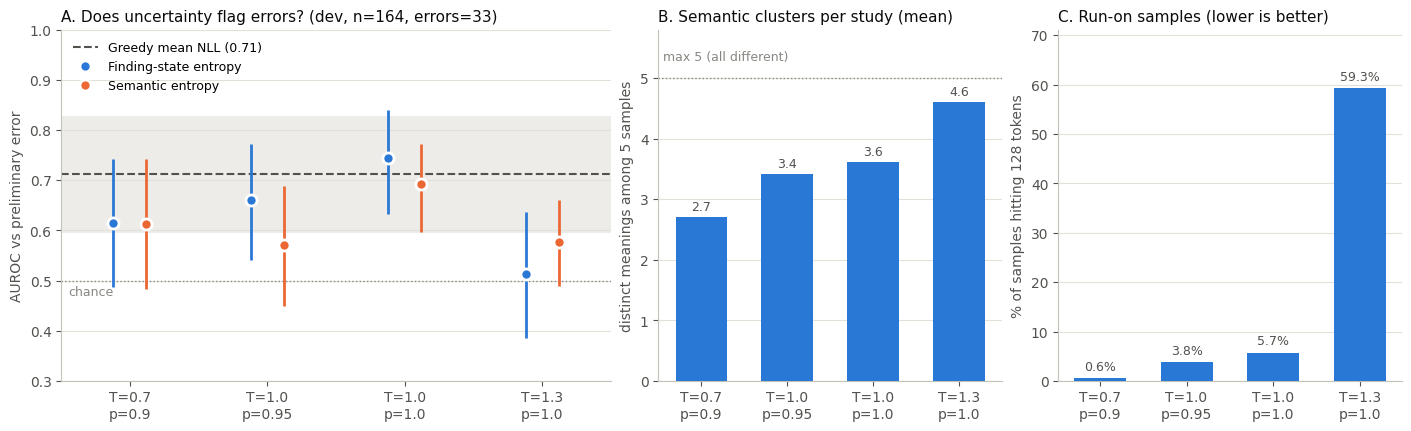

In [41]:
from sklearn.metrics import roc_auc_score
import numpy as np
import matplotlib.pyplot as plt

ref_labels = read_csv(OUT_DIR / "labels" / "labels_reference.csv")
greedy_labels = read_csv(OUT_DIR / "labels" / "labels_greedy.csv")

def preliminary_errors(split):
    usable = set(r[0] for r in eval_dataset(split).rows)
    ref = ref_labels[(ref_labels.split == split) & ref_labels.study_id.isin(usable)].set_index("study_id")[FINDINGS]
    gen = greedy_labels[(greedy_labels.split == split) & greedy_labels.study_id.isin(usable)].set_index("study_id")[FINDINGS]
    missing = usable - set(gen.index)
    assert not missing, f"{len(missing)} usable {split} studies have no greedy draft: rerun Step 8 and Step 10"
    ref, gen = ref.align(gen, join="inner", axis=0)
    unsupported = ((gen == "positive") & ref.isin(["negative", "unmentioned"])).any(axis=1)
    omission = ((ref == "positive") & gen.isin(["negative", "unmentioned"])).any(axis=1)
    return pd.DataFrame({"unsupported_prelim": unsupported, "omission_prelim": omission,
                         "any_error_prelim": unsupported | omission})

rng = np.random.default_rng(BASE_SEED)
def auroc_ci(y, score, reps=BOOTSTRAP_REPS):
    keep = score.notna()
    y, score = y[keep].to_numpy().astype(int), score[keep].to_numpy().astype(float)
    if len(set(y)) < 2:
        return float("nan"), float("nan"), float("nan")
    point = roc_auc_score(y, score)
    boots = []
    for _ in range(reps):
        idx = rng.integers(0, len(y), len(y))
        if len(set(y[idx])) == 2:
            boots.append(roc_auc_score(y[idx], score[idx]))
    lo, hi = np.percentile(boots, [2.5, 97.5])
    return point, lo, hi

errors = preliminary_errors("dev")
nll = greedy_labels.set_index("study_id")["mean_nll"].replace("", "nan").astype(float).rename("mean_nll")
n_ref_pos = (ref_labels[ref_labels.study_id.isin(errors.index)][FINDINGS] == "positive").any(axis=1).sum()
print(f"Usable dev studies: {len(errors)} (excluded as generator-trained: {len(EXCLUDED_IDS & set(ref_labels[ref_labels.split=='dev'].study_id))})")
print(f"Reference reports with a positive selected finding: {n_ref_pos} | preliminary errors: {errors.any_error_prelim.sum()} "
      f"(unsupported {errors.unsupported_prelim.sum()}, omission {errors.omission_prelim.sum()})")
assert n_ref_pos > 0, "No positive findings in dev reference labels: reference texts are missing or wrong."
if errors.any_error_prelim.sum() < 10:
    print("⚠️ Fewer than 10 error cases: AUROCs below will be very noisy.")

rows = []
for tag in SAMPLING_GRID:
    u = read_csv(uncertainty_path("dev", tag)).set_index("study_id")
    for c in ["finding_state_entropy", "semantic_entropy", "mean_sample_tokens"]:
        u[c] = u[c].astype(float)
    m = u.join(errors, how="inner").join(nll)
    y = m.any_error_prelim
    fse = auroc_ci(y, m.finding_state_entropy)
    se = auroc_ci(y, m.semantic_entropy)
    nl = auroc_ci(y, m.mean_nll)
    rows.append({
        "sampling_tag": tag, "temperature": SAMPLING_GRID[tag][0], "top_p": SAMPLING_GRID[tag][1],
        "studies": len(m), "errors": int(y.sum()),
        "pct_all_5_identical": 100 * (m.n_unique_texts.astype(int) == 1).mean(),
        "mean_semantic_clusters": m.n_semantic_clusters.astype(int).mean(),
        "mean_FSE": m.finding_state_entropy.mean(), "mean_SE": m.semantic_entropy.mean(),
        "pct_SE_max": 100 * (m.semantic_entropy > 0.999).mean(),
        "pct_samples_hit_max_tokens": 100 * m.n_hit_max_new_tokens.astype(int).sum() / (NUM_SAMPLES * len(m)),
        "mean_sample_tokens": m.mean_sample_tokens.mean(),
        "AUROC_FSE": fse[0], "AUROC_FSE_lo": fse[1], "AUROC_FSE_hi": fse[2],
        "AUROC_SE": se[0], "AUROC_SE_lo": se[1], "AUROC_SE_hi": se[2],
        "AUROC_greedyNLL": nl[0], "AUROC_greedyNLL_lo": nl[1], "AUROC_greedyNLL_hi": nl[2],
    })
sens = pd.DataFrame(rows)
sens.to_csv(OUT_DIR / "validation" / "sensitivity_dev.csv", index=False)
errors.to_csv(OUT_DIR / "validation" / "preliminary_errors_dev.csv")
display(sens[["sampling_tag", "studies", "errors", "AUROC_FSE", "AUROC_FSE_lo", "AUROC_FSE_hi",
              "AUROC_SE", "AUROC_SE_lo", "AUROC_SE_hi", "AUROC_greedyNLL", "mean_semantic_clusters",
              "pct_SE_max", "pct_samples_hit_max_tokens"]].round(3))

# ---- figure: three panels, one measure each ----
BLUE, ORANGE = "#2a78d6", "#eb6834"                      # validated categorical slots 1-2
INK, INK2, MUTED, GRID, AXIS = "#0b0b0b", "#52514e", "#898781", "#e1e0d9", "#c3c2b7"
plt.rcParams.update({"font.family": "sans-serif", "font.size": 10, "axes.edgecolor": AXIS,
                     "axes.labelcolor": INK2, "xtick.color": INK2, "ytick.color": INK2,
                     "axes.spines.top": False, "axes.spines.right": False})
x = np.arange(len(sens))
labels = [f"T={t}\np={p}" for t, p in zip(sens.temperature, sens.top_p)]
fig, axes = plt.subplots(1, 3, figsize=(14, 4.2), layout="constrained",
                         gridspec_kw={"width_ratios": [1.6, 1, 1]})

ax = axes[0]
for off, col, name, key in [(-0.12, BLUE, "Finding-state entropy", "FSE"), (0.12, ORANGE, "Semantic entropy", "SE")]:
    yv = sens[f"AUROC_{key}"]
    err = [yv - sens[f"AUROC_{key}_lo"], sens[f"AUROC_{key}_hi"] - yv]
    ax.errorbar(x + off, yv, yerr=err, fmt="o", ms=8, color=col, ecolor=col, elinewidth=2, capsize=0,
                mec="white", mew=2, label=name, zorder=3)
g = sens.AUROC_greedyNLL.iloc[0]
ax.axhspan(sens.AUROC_greedyNLL_lo.iloc[0], sens.AUROC_greedyNLL_hi.iloc[0], color=GRID, alpha=0.6, lw=0, zorder=1)
ax.axhline(g, color=INK2, lw=1.5, ls="--", zorder=2, label=f"Greedy mean NLL ({g:.2f})")
ax.axhline(0.5, color=MUTED, lw=1, ls=":", zorder=2)
ax.text(-0.45, 0.49, "chance", color=MUTED, fontsize=9, ha="left", va="top")
ax.set_xticks(x, labels); ax.set_xlim(-0.5, len(sens) - 0.5); ax.set_ylim(0.3, 1.0)
ax.set_ylabel("AUROC vs preliminary error"); ax.grid(axis="y", color=GRID, lw=0.8); ax.set_axisbelow(True)
ax.set_title(f"A. Does uncertainty flag errors? (dev, n={int(sens.studies.iloc[0])}, errors={int(sens.errors.iloc[0])})",
             loc="left", color=INK, fontsize=11)
ax.legend(frameon=False, fontsize=9, loc="upper left")

ax = axes[1]
ax.bar(x, sens.mean_semantic_clusters, width=0.6, color=BLUE, zorder=3)
for xi, v in zip(x, sens.mean_semantic_clusters):
    ax.text(xi, v + 0.06, f"{v:.1f}", ha="center", va="bottom", color=INK2, fontsize=9)
ax.axhline(NUM_SAMPLES, color=MUTED, lw=1, ls=":"); ax.text(-0.45, NUM_SAMPLES + 0.3, f"max {NUM_SAMPLES} (all different)", color=MUTED, fontsize=9, ha="left")
ax.set_xlim(-0.5, len(sens) - 0.5)
ax.set_xticks(x, labels); ax.set_ylim(0, NUM_SAMPLES + 0.8); ax.set_ylabel("distinct meanings among 5 samples")
ax.grid(axis="y", color=GRID, lw=0.8); ax.set_axisbelow(True)
ax.set_title("B. Semantic clusters per study (mean)", loc="left", color=INK, fontsize=11)

ax = axes[2]
ax.bar(x, sens.pct_samples_hit_max_tokens, width=0.6, color=BLUE, zorder=3)
for xi, v in zip(x, sens.pct_samples_hit_max_tokens):
    ax.text(xi, v + 1, f"{v:.1f}%", ha="center", va="bottom", color=INK2, fontsize=9)
ax.set_xticks(x, labels); ax.set_ylim(0, max(10, sens.pct_samples_hit_max_tokens.max() * 1.2))
ax.set_ylabel(f"% of samples hitting {MAX_NEW_TOKENS} tokens"); ax.grid(axis="y", color=GRID, lw=0.8); ax.set_axisbelow(True)
ax.set_title("C. Run-on samples (lower is better)", loc="left", color=INK, fontsize=11)

for ext in ("png", "svg"):
    fig.savefig(OUT_DIR / "validation" / f"sensitivity_dev.{ext}", dpi=200, facecolor="#fcfcfb")
plt.show()

## Step 13: Freeze ONE sampling setting (decide on dev only)
Look at the table and figure. A good setting has AUROCs at least as good as the others (overlapping intervals mean the difference isn't clear, so prefer the simpler/proposal default 0.7 / 0.9), few samples hitting the 128-token limit (panel C), not every study at the maximum number of meanings (panel B), and readable samples (Step 14).
Write the chosen tag below and run the cell. **Freeze it before looking at any test results.** The JSON is never overwritten with a different setting.

In [42]:
FROZEN_TAG = "t1.0_p1.00"   # <-- e.g. "t1.0_p0.95". Set this after reading the dev table.
assert FROZEN_TAG in SAMPLING_GRID, "Set FROZEN_TAG to one of: " + ", ".join(SAMPLING_GRID)

frozen_file = OUT_DIR / "frozen_sampling_settings.json"
settings = {"sampling_tag": FROZEN_TAG, "temperature": SAMPLING_GRID[FROZEN_TAG][0],
            "top_p": SAMPLING_GRID[FROZEN_TAG][1], "top_k": 0, "num_samples": NUM_SAMPLES,
            "max_new_tokens": MAX_NEW_TOKENS, "base_seed": BASE_SEED,
            "findings": FINDINGS, "aggregation": AGGREGATION, "nli_model": NLI_MODEL,
            "chexbert": labeler.version, "checkpoint_id": CHECKPOINT_ID,
            "checkpoint_sha": CHECKPOINT_SHA, "generator_commit": GENERATOR_COMMIT,
            "split_source": "official manifest_full.csv" if OFFICIAL else "generator's own train/dev",
            "excluded_generator_training_studies": EXCLUDE_GENERATOR_TRAINING_STUDIES,
            "selected_on": "dev"}
if frozen_file.exists():
    old = json.load(frozen_file.open())
    assert old["sampling_tag"] == FROZEN_TAG, (f"Already frozen as {old['sampling_tag']}; don't change it after seeing results. "
                                              "(Only if this file came from an old invalid run: delete person3_outputs in Drive and start fresh.)")
else:
    json.dump(settings, frozen_file.open("w"), indent=2)
print(json.dumps(settings, indent=2))

{
  "sampling_tag": "t1.0_p1.00",
  "temperature": 1.0,
  "top_p": 1.0,
  "top_k": 0,
  "num_samples": 5,
  "max_new_tokens": 128,
  "base_seed": 42,
  "findings": [
    "Atelectasis",
    "Cardiomegaly",
    "Consolidation",
    "Edema",
    "Pleural Effusion"
  ],
  "aggregation": "mean",
  "nli_model": "MoritzLaurer/DeBERTa-v3-base-mnli-fever-anli",
  "chexbert": "CheXbert StanfordAIMI/RRG_scorers/chexbert.pth sha256:6550703c92d6",
  "checkpoint_id": "iu-baseline-100ep-seed42",
  "checkpoint_sha": "db2f4c237d4f-a3a2ee047d65",
  "generator_commit": "46e3d8c62ec18e9d3f943da07c80e0d157cb4a28",
  "split_source": "official manifest_full.csv",
  "excluded_generator_training_studies": true,
  "selected_on": "dev"
}


## Step 14: Inspect extraction and clustering failures (dev, frozen setting)
This saves `inspection_dev.csv` with an empty `reviewer_note` column. Read the rows and write short notes for the methods and results write-up.
- **Over-split (paraphrases)**: samples that seem to say the same thing ended up in different clusters.
- **Negation**: samples disagree positive vs negative on a finding. Check that CheXbert and the clustering handled "no effusion" vs "effusion" correctly.
- **Uncertain finding**: a sample hedges ("possible", "may represent"). Check how it was labeled and clustered.
- **Under-merged**: one cluster, but CheXbert gives the samples different states for a selected finding.
- **CheXbert check**: reference reports CheXbert marks positive for a selected finding. Confirm by reading them.

In [43]:
pd.set_option("display.max_colwidth", 400)
ref_labels = read_csv(OUT_DIR / "labels" / "labels_reference.csv")
u = read_csv(uncertainty_path("dev", FROZEN_TAG)).set_index("study_id")
s = read_csv(samples_path("dev", FROZEN_TAG))
lab = read_csv(OUT_DIR / "labels" / f"labels_samples_dev_{FROZEN_TAG}.csv")
label_varies = lab.groupby("study_id")[FINDINGS].nunique().gt(1).any(axis=1)

n_clusters = u.n_semantic_clusters.astype(int)
over_split = n_clusters[n_clusters > 1].sort_values().index[:8]
# Under-merged: a cluster holding samples that disagree on positive vs not-positive for a selected finding
clusters = pd.DataFrame([(sid, str(k), c) for sid, a in u["cluster_assignment"].items()
                         for k, c in enumerate(a.split(","))], columns=["study_id", "sample_index", "cluster"])
cl = clusters.merge(lab.assign(sample_index=lab["sample_index"].astype(str)), on=["study_id", "sample_index"])
pos = cl[FINDINGS].eq("positive")
grp = pos.groupby([cl["study_id"], cl["cluster"]])
conflict = (grp.any() & ~grp.all()).any(axis=1)
conflict_studies = conflict[conflict].index.get_level_values("study_id").unique()
print(f"Studies with a cluster that mixes positive and not-positive samples: {len(conflict_studies)} of {len(u)} "
      f"({100 * len(conflict_studies) / len(u):.1f}%)")
under_merged = conflict_studies[:8]
# Proposal 4.3: review examples with negation (positive vs negative across samples) and uncertain findings
states_by_study = lab.groupby("study_id")[FINDINGS].agg(lambda x: set(x))
negation = states_by_study[states_by_study.apply(lambda r: any({"positive", "negative"} <= v for v in r), axis=1)].index[:8]
uncertain = states_by_study[states_by_study.apply(lambda r: any("uncertain" in v for v in r), axis=1)].index[:8]
chex_pos = ref_labels[(ref_labels.split == "dev") & ref_labels.study_id.isin(u.index)
                      & (ref_labels[FINDINGS] == "positive").any(axis=1)].study_id[:8]

rows = []
for kind, ids in [("over_split? (paraphrase)", over_split), ("under_merged?", under_merged),
                  ("negation", negation), ("uncertain_finding", uncertain)]:
    for sid in ids:
        g = s[s.study_id == sid].sort_values("sample_index")
        assign = u.loc[sid, "cluster_assignment"].split(",")
        for (_, r), cid in zip(g.iterrows(), assign):
            l = lab[(lab.study_id == sid) & (lab.sample_index == r.sample_index)].iloc[0]
            rows.append({"check": kind, "study_id": sid, "sample_index": r.sample_index, "cluster": cid,
                         "text": r.generated_text, **{f: l[f] for f in FINDINGS}, "reviewer_note": ""})
for sid in chex_pos:
    r = ref_labels[ref_labels.study_id == sid].iloc[0]
    rows.append({"check": "chexbert_reference_positive", "study_id": sid, "sample_index": "", "cluster": "",
                 "text": manifest.set_index("study_id").loc[sid, "reference_text"],
                 **{f: r[f] for f in FINDINGS}, "reviewer_note": ""})
inspection = pd.DataFrame(rows)
inspection.to_csv(OUT_DIR / "validation" / "inspection_dev.csv", index=False)
print(f"over-split: {len(over_split)} | under-merged: {len(under_merged)} | negation: {len(negation)} | "
      f"uncertain: {len(uncertain)} | reference positives: {len(chex_pos)}")
display(inspection.head(40))

Studies with a cluster that mixes positive and not-positive samples: 29 of 164 (17.7%)
over-split: 8 | under-merged: 8 | negation: 8 | uncertain: 8 | reference positives: 8


,check,study_id,sample_index,cluster,text,Atelectasis,Cardiomegaly,Consolidation,Edema,Pleural Effusion,reviewer_note
0,over_split? (paraphrase),CXR1352,0,0,"Impression: Heart size normal. Crop aorta is an overweight. Of the right throposis, the lungs are clear. No visible infiltrates since in the right face.",unmentioned,negative,negative,unmentioned,unmentioned,
1,over_split? (paraphrase),CXR1352,1,1,Findings: Heart size and mediastinal contour are normal. The lungs are clear. No focal consolidation. No pleural effusion or pneumothorax. There are no acute bony abnormalities. Impression: No acute cardiopulmonary findings.,unmentioned,negative,negative,unmentioned,negative,
2,over_split? (paraphrase),CXR1352,2,1,Findings: The heart is normal in size. The mediastinum is unremarkable. The lungs are clear. Impression: No acute disease.,unmentioned,negative,unmentioned,unmentioned,unmentioned,
3,over_split? (paraphrase),CXR1352,3,1,Findings: Cardiac XXXX and mediastinal contours appear within normal limits. The lungs are free of focal airspace disease. No pleural effusion or pneumothorax is seen. XXXX are unremarkable. Impression: 1. No evidence of active disease.,unmentioned,negative,unmentioned,unmentioned,negative,
4,over_split? (paraphrase),CXR1352,4,1,"Impression: Heart size is normal with aorta regarding hemidiaphragm, pulmonary edema, visible airspace disease and tie. Lungs are clear. No pleural effusions or pneumothoraces. The heart and mediastinum are normal.",unmentioned,negative,unmentioned,positive,negative,
5,over_split? (paraphrase),CXR2197,0,0,"Findings: The cardiomediastinal silhouette is within normal limits in size. The lungs are hyperexpanded. Locenhoema is flattening and stable. No focal consolidation, effusion, or pneumothorax identified. Killer vertebral body is unremarkable. Impression: 1. No acute cardiopulmonary findings.",unmentioned,negative,negative,unmentioned,negative,
6,over_split? (paraphrase),CXR2197,1,1,Findings: The cardiomediastinal silhouette is within normal limits for appearance. No focal areas of consolidation. No pneumothorax or pleural effusion. Impression: No acute cardiopulmonary abnormalities.,unmentioned,unmentioned,negative,unmentioned,negative,
7,over_split? (paraphrase),CXR2197,2,0,Findings: Normal cardiomediastinal silhouette and pulmonary vasculature. No pneumothorax. No focal airspace disease. There is a fracture of right upper left clavicle. No pleural effusion. The osseous structures are intact. Impression: Impression: 1. No acute cardiopulmonary abnormality.,unmentioned,negative,unmentioned,unmentioned,negative,
8,over_split? (paraphrase),CXR2197,3,0,"Findings: The heart is normal in size. Of the mediastinum, there is no pleural effusion or pneumothorax. The XXXX are intact. The right lateral right lower lobe XXXX is unremarkable. Impression: No acute pulmonary disease.",unmentioned,negative,unmentioned,unmentioned,negative,
9,over_split? (paraphrase),CXR2197,4,1,Findings: There is least XXXX XXXX irregularities in the lateral passage. There is hyperexpansion of the right upper lobe of the lateral image. There is incalcified size of the anterior right central lobe showing large pleural effusions. The heart and mediastinum of normal size and contour. There are minimal degenerative changes of the spine with visible burns and shallow nodules. Impression: ...,unmentioned,negative,unmentioned,unmentioned,positive,


## Step 15: Final splits with the frozen setting (test and risk_cal)
Run only after Step 13. For each split in `FINAL_SPLITS`, this generates any missing greedy drafts, samples with the frozen setting, labels everything and builds the uncertainty file. risk_cal is included because Person 4's risk-control calibration needs S on it. Studies the generator was trained on are left out (see Step 5's table).

In [44]:
frozen_file = OUT_DIR / "frozen_sampling_settings.json"
if not frozen_file.exists():
    print("First freeze a sampling setting in Step 13 (on dev).")
else:
    frozen = json.load(frozen_file.open())
    FROZEN_TAG = frozen["sampling_tag"]
    todo = [sp for sp in FINAL_SPLITS if sp in SPLITS]
    if not todo:
        print("No test / risk_cal split in the manifest yet: put the official manifest_full.csv in", HANDOFF_DIR)
    for split in todo:
        ensure_greedy(split)
        sample_split(split, FROZEN_TAG, frozen["temperature"], frozen["top_p"])
    if todo:
        label_everything()
        for split in todo:
            u = build_uncertainty(split, FROZEN_TAG)
            print(f"\n{split}: {len(u)} studies")
            print(u[["finding_state_entropy", "semantic_entropy"]].describe().round(3))

test: 258 usable studies, 258 already have a greedy draft, generating 0


greedy test: 0it [00:00, ?it/s]

test t1.0_p1.00:   0%|          | 0/258 [00:00<?, ?it/s]

Saved /content/drive/MyDrive/CXR-Sentry/person3_outputs/samples/samples_test_t1.0_p1.00.csv
risk_cal: 161 usable studies, 161 already have a greedy draft, generating 0


greedy risk_cal: 0it [00:00, ?it/s]

risk_cal t1.0_p1.00:   0%|          | 0/161 [00:00<?, ?it/s]

... (17 outputs left out)

NLI: 0it [00:00, ?it/s]


test: 258 studies
       finding_state_entropy  semantic_entropy
count                258.000           258.000
mean                   0.275             0.733
std                    0.095             0.171
min                    0.072             0.311
25%                    0.217             0.590
50%                    0.266             0.828
75%                    0.331             0.828
max                    0.561             1.000


NLI: 0it [00:00, ?it/s]


risk_cal: 161 studies
       finding_state_entropy  semantic_entropy
count                161.000           161.000
mean                   0.279             0.754
std                    0.095             0.180
min                    0.072             0.311
25%                    0.217             0.590
50%                    0.266             0.828
75%                    0.339             0.828
max                    0.571             1.000


## Step 16: Handoff
This copies the files each person needs into `person3_outputs/handoff_*` folders. Share those folders on Drive.
Every file includes `study_id`, `split`, the checkpoint or labeler version, and CheXbert's standard finding names.

In [45]:
frozen = json.load((OUT_DIR / "frozen_sampling_settings.json").open())
tag = frozen["sampling_tag"]
to_p2 = OUT_DIR / "handoff_person2"
to_p4 = OUT_DIR / "handoff_person4"
for d in (to_p2, to_p4):
    d.mkdir(exist_ok=True)

shared = [OUT_DIR / "labels" / "labels_reference.csv", OUT_DIR / "labels" / "labels_greedy.csv",
          OUT_DIR / "frozen_sampling_settings.json"]
for p in shared:
    shutil.copy(p, to_p2); shutil.copy(p, to_p4)
for split in ("dev", "test", "risk_cal"):
    for p in [uncertainty_path(split, tag), samples_path(split, tag),
              OUT_DIR / "labels" / f"labels_samples_{split}_{tag}.csv"]:
        if p.exists():
            shutil.copy(p, to_p4)
for p in list((OUT_DIR / "validation").glob("sensitivity_dev.*")) + [OUT_DIR / "validation" / "generator_overlap.csv"]:
    shutil.copy(p, to_p4)
shutil.copy(OUT_DIR / "validation" / "generator_overlap.csv", to_p2)

for d in (to_p2, to_p4):
    print(d.name, "→", sorted(x.name for x in d.iterdir()))

handoff_person2 → ['frozen_sampling_settings.json', 'generator_overlap.csv', 'labels_greedy.csv', 'labels_reference.csv']
handoff_person4 → ['frozen_sampling_settings.json', 'generator_overlap.csv', 'labels_greedy.csv', 'labels_reference.csv', 'labels_samples_dev_t1.0_p1.00.csv', 'labels_samples_risk_cal_t1.0_p1.00.csv', 'labels_samples_test_t1.0_p1.00.csv', 'samples_dev_t1.0_p1.00.csv', 'samples_risk_cal_t1.0_p1.00.csv', 'samples_test_t1.0_p1.00.csv', 'sensitivity_dev.csv', 'sensitivity_dev.png', 'sensitivity_dev.svg', 'uncertainty_dev_t1.0_p1.00.csv', 'uncertainty_risk_cal_t1.0_p1.00.csv', 'uncertainty_test_t1.0_p1.00.csv']
